# 02 · Inter-rater agreement analysis and sample-size planning (E3)
**Supports:** RQ3. **Design:** blinded assessors rate the same scenarios under condition **A** (qualitative, v1.0 sheet only) and **B** (structured: explicit assumptions, evidence links, ranges).
This notebook (1) shows the exact analysis that will be run on `experiments/data-templates/e3_ratings.csv`, and (2) simulates how many raters × scenarios are needed to detect a difference in agreement. **All data below is simulated.**

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from crasme import plotting; plotting.use()
pd.set_option('display.precision', 3); pd.set_option('display.width', 140)
from crasme import agreement as a

## 1 · Analysis pipeline on a simulated dataset (long format, same columns as the data template)

In [2]:
rng = np.random.default_rng(7)
def simulate(n_items=24, n_raters=6, noise=0.9, cond='A'):
    truth = rng.normal(3, 1.1, n_items)
    rows = []
    for rt in range(n_raters):
        bias = rng.normal(0, 0.3)
        for it in range(n_items):
            v = int(np.clip(np.rint(truth[it] + bias + rng.normal(0, noise)), 1, 5))
            rows.append({'condition': cond, 'rater_id': f'R{rt+1}', 'scenario_id': f'SC{it+1:02d}', 'dimension': 'likelihood', 'rating': v})
    return pd.DataFrame(rows)
df = pd.concat([simulate(noise=0.95, cond='A'), simulate(noise=0.6, cond='B')])
df.head()

,condition,rater_id,scenario_id,dimension,rating
0,A,R1,SC01,likelihood,3
1,A,R1,SC02,likelihood,1
2,A,R1,SC03,likelihood,2
3,A,R1,SC04,likelihood,2
4,A,R1,SC05,likelihood,3


In [3]:
def agreement(d):
    m = d.pivot(index='rater_id', columns='scenario_id', values='rating').to_numpy(float)
    alpha = a.bootstrap_ci(lambda x: a.krippendorff_alpha(x, 'ordinal'), m, n_boot=1000, axis=1)
    icc = a.bootstrap_ci(lambda x: a.icc(x, 'ICC2_1'), m.T, n_boot=1000, axis=0)
    return pd.Series({'alpha_ord': alpha[0], 'alpha_lo': alpha[1], 'alpha_hi': alpha[2],
                      'icc21': icc[0], 'icc_lo': icc[1], 'icc_hi': icc[2], 'icc_label': a.interpret_icc(icc[0])})
summary = df.groupby('condition').apply(agreement, include_groups=False); summary

,alpha_ord,alpha_lo,alpha_hi,icc21,icc_lo,icc_hi,icc_label
condition,,,,,,,
A,0.415,0.208,0.567,0.445,0.249,0.592,poor
B,0.601,0.389,0.727,0.624,0.441,0.738,moderate


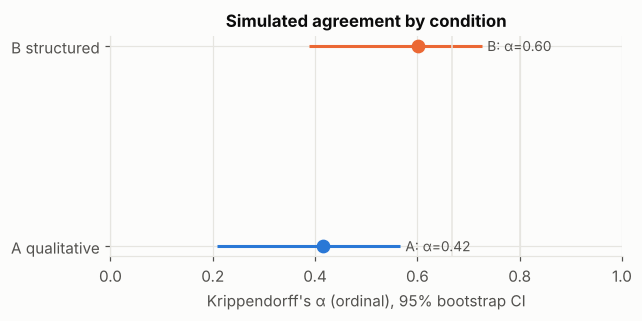

In [4]:
fig, ax = plt.subplots(figsize=(6, 2.6))
for i, (cond, row) in enumerate(summary.iterrows()):
    ax.errorbar(row.alpha_ord, i, xerr=[[row.alpha_ord-row.alpha_lo], [row.alpha_hi-row.alpha_ord]], fmt='o',
                color=plotting.SERIES[i], capsize=0, lw=2)
    ax.text(row.alpha_hi + 0.01, i, f'{cond}: α={row.alpha_ord:.2f}', va='center', fontsize=9, color=plotting.INK2)
ax.set_yticks([0, 1], ['A qualitative', 'B structured']); ax.set_xlim(0, 1)
for t in (0.667, 0.8): ax.axvline(t, color=plotting.GRID, lw=1)
ax.set_xlabel("Krippendorff's α (ordinal), 95% bootstrap CI"); ax.set_title('Simulated agreement by condition'); plt.show()

Thresholds drawn at α = 0.667 and 0.8 (Krippendorff's conventional limits for tentative and reliable conclusions). Pairwise weighted κ (quadratic) is also reported for 2-rater subsets:

In [5]:
d = df[df.condition=='A'].pivot(index='scenario_id', columns='rater_id', values='rating')
print('Quadratic-weighted κ R1 vs R2 (A):', round(a.weighted_kappa(d.R1, d.R2, range(1,6)), 3))

Quadratic-weighted κ R1 vs R2 (A): 0.308


## 2 · Sample-size planning
How often does the 95 % CI of the α difference (B − A) exclude 0, for a given number of raters and scenarios? (Noise levels 0.95 → 0.6 correspond to α ≈ 0.55 → 0.75; replace with pilot estimates.)

In [6]:
def power(n_items, n_raters, sims=60):
    hits = 0
    for s in range(sims):
        A = simulate(n_items, n_raters, 0.95, 'A'); B = simulate(n_items, n_raters, 0.6, 'B')
        ma = A.pivot(index='rater_id', columns='scenario_id', values='rating').to_numpy(float)
        mb = B.pivot(index='rater_id', columns='scenario_id', values='rating').to_numpy(float)
        diffs = []
        for _ in range(150):
            idx = rng.integers(0, n_items, n_items)
            diffs.append(a.krippendorff_alpha(mb[:, idx], 'ordinal') - a.krippendorff_alpha(ma[:, idx], 'ordinal'))
        hits += np.quantile(diffs, 0.025) > 0
    return hits / sims
grid = pd.DataFrame([{'scenarios': n, 'raters': k, 'power': power(n, k)} for n in (12, 24, 48) for k in (3, 6, 9)])
grid.pivot(index='scenarios', columns='raters', values='power')

raters,3,6,9
scenarios,,,
12,0.117,0.183,0.183
24,0.183,0.267,0.350
48,0.383,0.617,0.567


**Planning reading:** choose the smallest design with power ≥ 0.8 under the noise measured in the first 1–2 pilot sessions. Under these assumed effects even 48 scenarios × 9 raters may fall short — agreement differences of ~0.2 in α need many more scenarios than a typical SME pilot provides, so plan E3 as a **pooled cross-SME rater study** (practitioners from several pilots rating a shared scenario bank), not as a per-SME measurement. Pre-register the noise estimate and the decision rule (`experiments/protocols/PREREGISTRATION-template.md`).